## Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("E:\\Predicting Jet Engine Failure\\data\\Processed Data\\train_features.csv")

In [3]:
df.head(5)

,unit,cycle,set1,set2,set3,s2,s3,s4,s5,s6,...,s15_mean_15,s15_std_15,s16_mean_15,s16_std_15,s17_mean_15,s17_std_15,s20_mean_15,s20_std_15,s21_mean_15,s21_std_15
0,1,1,-0.0007,-0.0004,100.0,641.82,1589.70,1400.60,14.62,21.61,...,8.419500,0.000000,0.03,0.0,392.000000,0.000000,39.060000,0.000000,23.419000,0.000000
1,1,2,0.0019,-0.0003,100.0,642.15,1591.82,1403.14,14.62,21.61,...,8.425650,0.008697,0.03,0.0,392.000000,0.000000,39.030000,0.042426,23.421300,0.003253
2,1,3,-0.0043,0.0003,100.0,642.35,1587.99,1404.20,14.62,21.61,...,8.423033,0.007640,0.03,0.0,391.333333,1.154701,39.003333,0.055076,23.395600,0.044573
3,1,4,0.0007,0.0000,100.0,642.35,1582.79,1401.87,14.62,21.61,...,8.409325,0.028117,0.03,0.0,391.500000,1.000000,38.972500,0.076322,23.390175,0.037977
4,1,5,-0.0019,-0.0002,100.0,642.37,1582.85,1406.22,14.62,21.61,...,8.413340,0.025953,0.03,0.0,391.800000,1.095445,38.958000,0.073621,23.393020,0.033498


## Split Data By Engines

In [10]:
from sklearn.model_selection import GroupShuffleSplit

# df contains the feature-engineered training data
# Group rows by engine ID to prevent data leakage
groups = df["unit"]

# Split 80% of engines for training and 20% for validation
splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.2, random_state=42
)

# Get row indices while keeping each engine in one split
train_idx, val_idx = next(
    splitter.split(df, groups=groups)
)

# Create separate training and validation DataFrames
train_data = df.iloc[train_idx].copy()
val_data = df.iloc[val_idx].copy()



In [11]:
print("Training engines:", train_data["unit"].nunique())
print("Validation engines:", val_data["unit"].nunique())

print("Training rows:", len(train_data))
print("Validation rows:", len(val_data))

Training engines: 80
Validation engines: 20
Training rows: 16561
Validation rows: 4070


**Verfiy engine overlapping in Sets**

In [12]:
# Verify no engine appears in both sets
assert set(train_data["unit"]).isdisjoint(
    set(val_data["unit"])
)

print("Engine-level split verified!")

Engine-level split verified!


In [13]:
train_data

,unit,cycle,set1,set2,set3,s2,s3,s4,s5,s6,...,s15_mean_15,s15_std_15,s16_mean_15,s16_std_15,s17_mean_15,s17_std_15,s20_mean_15,s20_std_15,s21_mean_15,s21_std_15
192,2,1,-0.0018,0.0006,100.0,641.89,1583.84,1391.28,14.62,21.60,...,8.390500,0.000000,0.03,0.0,391.000000,0.000000,38.940000,0.000000,23.458500,0.000000
193,2,2,0.0043,-0.0003,100.0,641.82,1587.05,1393.13,14.62,21.61,...,8.403600,0.018526,0.03,0.0,391.500000,0.707107,39.000000,0.084853,23.433500,0.035355
194,2,3,0.0018,0.0003,100.0,641.55,1588.32,1398.96,14.62,21.60,...,8.395800,0.018818,0.03,0.0,391.333333,0.577350,39.036667,0.087369,23.430667,0.025477
195,2,4,0.0035,-0.0004,100.0,641.68,1584.15,1396.08,14.62,21.61,...,8.397300,0.015655,0.03,0.0,391.250000,0.500000,39.060000,0.085245,23.448675,0.041592
196,2,5,0.0005,0.0004,100.0,641.73,1579.03,1402.52,14.62,21.60,...,8.395180,0.014363,0.03,0.0,391.000000,0.707107,39.084000,0.091269,23.443620,0.037752
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20626,100,196,-0.0004,-0.0003,100.0,643.49,1597.98,1428.63,14.62,21.61,...,8.502800,0.022690,0.03,0.0,395.733333,1.279881,38.465333,0.131468,23.105207,0.070544
20627,100,197,-0.0016,-0.0005,100.0,643.54,1604.50,1433.58,14.62,21.61,...,8.504693,0.022326,0.03,0.0,395.666667,1.290994,38.458000,0.137695,23.107240,0.071705
20628,100,198,0.0004,0.0000,100.0,643.42,1602.46,1428.18,14.62,21.61,...,8.508960,0.027094,0.03,0.0,395.866667,1.407463,38.454667,0.137470,23.098067,0.084370
20629,100,199,-0.0011,0.0003,100.0,643.23,1605.26,1426.53,14.62,21.61,...,8.511627,0.027987,0.03,0.0,395.800000,1.424279,38.444667,0.143918,23.094140,0.084502


**Split Data Into Train and Validation Sets**

In [84]:
X_train = train_data.drop(columns=["unit", "RUL"])
y_train = train_data["RUL"]

X_val = val_data.drop(columns=["unit", "RUL"])
y_val = val_data["RUL"]

## Baseline Model Setup

**Dummy Regressor**

In [85]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error

# Create a baseline that always predicts the mean RUL
baseline = DummyRegressor(strategy="mean")

# Train the baseline
baseline.fit(X_train, y_train)

# Predict RUL for validation data
y_pred_baseline = baseline.predict(X_val)

# Calculate RMSE
baseline_rmse =  root_mean_squared_error(y_val, y_pred_baseline)


print(f"Baseline RMSE: {baseline_rmse:.2f} cycles")

Baseline RMSE: 41.72 cycles


**Linear Regressor**

In [86]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error

lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

# Predict RUL for validation data
y_pred_lr = lr_model.predict(X_val)

# Calculate RMSE
lr_rmse = root_mean_squared_error(y_val, y_pred_lr)

print(f"Baseline RMSE: {baseline_rmse:.2f} cycles")
print(f"Linear Regression RMSE: {lr_rmse:.2f} cycles")

Baseline RMSE: 41.72 cycles
Linear Regression RMSE: 17.66 cycles


**LGBMRegressor**

In [87]:
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_squared_error
import numpy as np

# Initialize LightGBM
lgbm_model = LGBMRegressor(
    n_estimators=1000,
    learning_rate=0.01,
    num_leaves=31,
    max_depth=-1,
    random_state=42,
    verbosity=-1,
)

# Train the model
lgbm_model.fit(X_train, y_train)

# Predict validation RUL
y_pred_lgbm = lgbm_model.predict(X_val)

# Calculate RMSE
lgbm_rmse = np.sqrt(
    mean_squared_error(y_val, y_pred_lgbm)
)

print(f"Baseline RMSE: {baseline_rmse:.2f}")
print(f"Linear Regression RMSE: {lr_rmse:.2f}")
print(f"LightGBM RMSE: {lgbm_rmse:.2f}")


Baseline RMSE: 41.72
Linear Regression RMSE: 17.66
LightGBM RMSE: 15.99


**GroupKFold**

A cross-validation technique that splits data into multiple folds while keeping all records from the same engine in a single fold. We used it to prevent data leakage between training and validation sets and to evaluate model performance across different engines.

In [88]:
from sklearn.model_selection import GroupKFold, RandomizedSearchCV
from sklearn.metrics import root_mean_squared_error  
from lightgbm import LGBMRegressor


# Five folds, with each engine kept entirely within one fold
gkf = GroupKFold(n_splits=5)

print("Unique engines:", groups.nunique())
print("Number of folds:", gkf.get_n_splits())

Unique engines: 100
Number of folds: 5


**RandomizedSearchCV**

A hyperparameter tuning technique that randomly tests a selected number of parameter combinations using cross-validation. We used it with GroupKFold to find LightGBM hyperparameters that improve RUL prediction accuracy, measured using RMSE (Root Mean Squared Error).

In [89]:
#RandomizedSearchCV
param_distributions = {
    "n_estimators": [300, 500, 800, 1000, 1200],
    "learning_rate": [0.01, 0.02, 0.03, 0.05, 0.08],
    "num_leaves": [15, 20, 31, 40, 50, 63],
    "max_depth": [-1, 5, 7, 10, 12],
    "min_child_samples": [10, 20, 30, 50, 75],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "reg_alpha": [0, 0.01, 0.1, 1.0],
    "reg_lambda": [0, 0.01, 0.1, 1.0, 5.0],
}

lgbm_model = LGBMRegressor(objective='regression', random_state=42, verbosity=-1, n_jobs=-1)


search = RandomizedSearchCV(
    estimator=lgbm_model,
    param_distributions=param_distributions,
    n_iter=50,
    scoring="neg_root_mean_squared_error",
    cv=gkf,
    verbose=2,
    random_state=42,
    n_jobs=1, 
    refit=True,
    return_train_score=True
)

# Match the groups to the rows in X_train
search.fit(X_train, y_train, groups=train_data["unit"])

print(f"Best 5-fold CV RMSE: {-search.best_score_:.2f}")
print("\nBest parameters:")
print(search.best_params_)


Fitting 5 folds for each of 50 candidates, totalling 250 fits
[CV] END colsample_bytree=0.7, learning_rate=0.03, max_depth=-1, min_child_samples=10, n_estimators=1200, num_leaves=15, reg_alpha=0.01, reg_lambda=5.0, subsample=0.9; total time=   2.1s
[CV] END colsample_bytree=0.7, learning_rate=0.03, max_depth=-1, min_child_samples=10, n_estimators=1200, num_leaves=15, reg_alpha=0.01, reg_lambda=5.0, subsample=0.9; total time=   1.9s
[CV] END colsample_bytree=0.7, learning_rate=0.03, max_depth=-1, min_child_samples=10, n_estimators=1200, num_leaves=15, reg_alpha=0.01, reg_lambda=5.0, subsample=0.9; total time=   2.1s
[CV] END colsample_bytree=0.7, learning_rate=0.03, max_depth=-1, min_child_samples=10, n_estimators=1200, num_leaves=15, reg_alpha=0.01, reg_lambda=5.0, subsample=0.9; total time=   1.5s
[CV] END colsample_bytree=0.7, learning_rate=0.03, max_depth=-1, min_child_samples=10, n_estimators=1200, num_leaves=15, reg_alpha=0.01, reg_lambda=5.0, subsample=0.9; total time=   1.8s
[CV

In [92]:
# Get the best model from the search
best_lgbm = search.best_estimator_

In [94]:
# Train the best model on the full training set
best_lgbm.fit(X_train, y_train)

# Predict RUL for validation data
best_lgbm_pred = best_lgbm.predict(X_val)

# Calculate RMSE
best_lgbm_rmse = root_mean_squared_error(y_val, best_lgbm_pred)

print(f"Best LightGBM RMSE on validation set: {best_lgbm_rmse:.2f} cycles")

Best LightGBM RMSE on validation set: 15.34 cycles


## Evaluate Model Using Test Data


In [95]:
test = pd.read_csv(
    "E:\\Predicting Jet Engine Failure\\data\\Processed Data\\test_features.csv"
)

rul_true = pd.read_csv(
    "E:\\Predicting Jet Engine Failure\\data\\Raw Data\\RUL_FD001.txt",
    sep=r"\s+",
    header=None
)[0].to_numpy()

# Sort the test set by engine ID and cycle number
test = test.sort_values(["unit", "cycle"]).copy()

# Get the last observed cycle for each engine in the test set
test_last = (
    test.groupby("unit", sort=True)
    .tail(1)
    .sort_values("unit")
    .copy()
    .reset_index(drop=True)
)

# Verify alignment with official labels
assert len(test_last) == len(rul_true), (
    f"Found {len(test_last)} test engines but "
    f"{len(rul_true)} RUL labels."
)

print("Test engines:", len(test_last))
print("True RUL labels:", len(rul_true))

Test engines: 100
True RUL labels: 100


In [96]:
# Identify sensor columns in the training set 
sensors = [
    col for col in X_train.columns
    if col.startswith("s") and col[1:].isdigit()
]

# Sort the test set by engine ID and cycle number
test = test.sort_values(["unit", "cycle"]).copy()

# Calculate rolling statistics for each sensor
for sensor in sensors:
    test[f"{sensor}_mean_15"] = (
        test.groupby("unit")[sensor]
        .transform(lambda x: x.rolling(15, min_periods=1).mean())
    )

    test[f"{sensor}_std_15"] = (
        test.groupby("unit")[sensor]
        .transform(lambda x: x.rolling(15, min_periods=1).std())
        .fillna(0)
    )

# Get the last observed cycle for each engine in the test set
test_last = (
    test.groupby("unit", sort=True)
    .tail(1)
    .sort_values("unit")
    .reset_index(drop=True)
)


In [98]:
# Match test features to the model's training feature columns
feature_cols = test.columns
X_test_final = test_last.drop(columns=["unit"])

assert not X_test_final.isna().any().any(), (
    "Missing test features. Check that training and test "
    "feature engineering match."
)

# Predict RUL for each engine's final observed cycle
y_pred =best_lgbm.predict(X_test_final)

# Evaluate against the official RUL labels
test_rmse = root_mean_squared_error(rul_true, y_pred)

print(f"Official test RMSE: {test_rmse:.2f} cycles")

Official test RMSE: 17.84 cycles


**Scatter Plot Between Rul_true values vs y_pred values**

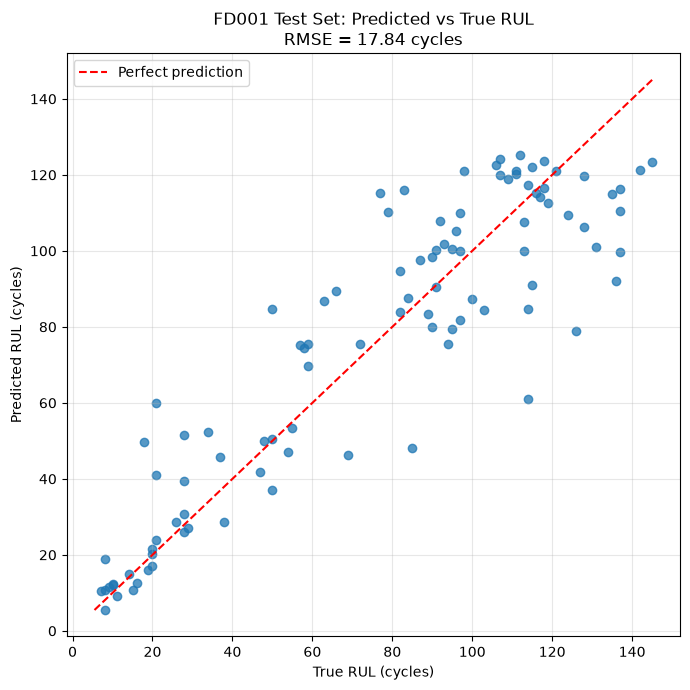

In [99]:
plt.figure(figsize=(7, 7))

plt.scatter(rul_true, y_pred, alpha=0.75)

# Ideal predictions lie on this diagonal
lower = min(rul_true.min(), y_pred.min())
upper = max(rul_true.max(), y_pred.max())
plt.plot([lower, upper], [lower, upper], "r--", label="Perfect prediction")

plt.xlabel("True RUL (cycles)")
plt.ylabel("Predicted RUL (cycles)")
plt.title(f"FD001 Test Set: Predicted vs True RUL\nRMSE = {test_rmse:.2f} cycles")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Comparison Between True_RUL vs Predicted_RUL

In [100]:
comparison = pd.DataFrame({
    "unit": test_last["unit"],
    "true_RUL": rul_true,
    "predicted_RUL": y_pred
})

comparison["error"] = comparison["predicted_RUL"] - comparison["true_RUL"]
comparison["absolute_error"] = comparison["error"].abs()

display(comparison.head(10))

print(f"Mean absolute error: {comparison['absolute_error'].mean():.2f} cycles")
print(
    "Largest absolute error:",
    f"{comparison['absolute_error'].max():.2f} cycles"
)

,unit,true_RUL,predicted_RUL,error,absolute_error
0,1,112,125.197632,13.197632,13.197632
1,2,98,121.019358,23.019358,23.019358
2,3,69,46.241093,-22.758907,22.758907
3,4,82,83.892345,1.892345,1.892345
4,5,91,90.542177,-0.457823,0.457823
5,6,93,101.894398,8.894398,8.894398
6,7,91,100.111591,9.111591,9.111591
7,8,95,79.370340,-15.629660,15.629660
8,9,111,120.291836,9.291836,9.291836
9,10,96,105.125562,9.125562,9.125562


Mean absolute error: 13.34 cycles
Largest absolute error: 53.02 cycles


In [101]:
from sklearn.metrics import (
    root_mean_squared_error,
    mean_absolute_error
)
import numpy as np

rmse = root_mean_squared_error(
    comparison["true_RUL"],
    comparison["predicted_RUL"]
)

mae = mean_absolute_error(
    comparison["true_RUL"],
    comparison["predicted_RUL"]
)

bias = comparison["error"].mean()

print(f"Test RMSE: {rmse:.2f} cycles")
print(f"Test MAE:  {mae:.2f} cycles")
print(f"Mean prediction error: {bias:.2f} cycles")

Test RMSE: 17.84 cycles
Test MAE:  13.34 cycles
Mean prediction error: 0.06 cycles


In [109]:
import pandas as pd
import numpy as np




def RollingFeatureEngineer(X, window=15):
        sensors = [
    "s2", "s3", "s4", "s6", "s7",
    "s8", "s9", "s11", "s12", "s13",
    "s14", "s15", "s17", "s20", "s21"
    ]
        
        data = X.copy()

        # Sort so rolling calculations follow cycle order
        data = data.sort_values(["unit", "cycle"]).copy()

        for sensor in sensors:
            data[f"{sensor}_mean_{window}"] = (
                data.groupby("unit")[sensor]
                .transform(
                    lambda x: x.rolling(
                        window=window,
                        min_periods=1
                    ).mean()
                )
            )

            data[f"{sensor}_std_{window}"] = (
                data.groupby("unit")[sensor]
                .transform(
                    lambda x: x.rolling(
                        window=window,
                        min_periods=1
                    ).std()
                )
                .fillna(0)
            )

        return data

In [113]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

def drop_unit_column(X):
    return X.drop(columns=["unit"])

def drop_unused_columns(X):
    return X.drop(columns=["unit", "RUL"], errors="ignore")

final_model = Pipeline([
    (
        "rolling_features",
        FunctionTransformer(
            RollingFeatureEngineer,
            kw_args={"window": 15},
            validate=False
        )
    ),
    ("drop_unused", FunctionTransformer(drop_unused_columns, validate=False)),
    ("model", best_lgbm)
])

KeyError: 'unit'